# Análise de conversão de assinaturas

**Objetivo:** entender o que leva uma sessão a converter e avaliar duas estratégias de modelagem — prever a conversão **na sessão atual** (tempo real) e prever se o usuário **vai converter nas próximas sessões** (a priori, só com histórico).

**Dataset:** 10.000 sessões de 299 usuários (`data.csv`), com métricas de engajamento da sessão (`total_time_spent`, `articles_viewed`, `avg_scroll_depth`, `is_weekend`, `device`) e a flag `converted`.

**Estrutura:**
1. Dados e visão geral
2. Exploração guiada por perguntas (respondidas com gráficos)
3. Features de histórico do usuário e alvo futuro sem viés de censura (`will_convert_next_k`)
4. Modelagem: Regressão Logística × CatBoost, com métricas para classes desbalanceadas, e teste de leakage intra-sessão (4.1)
5. Teto de sinal — por que o modelo futuro não funciona
6. **Respostas às 8 perguntas do teste** (síntese em pontos-chave para apresentação, com evidências)

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

AZUL, CINZA = '#2a78d6', '#c3c2b7'

## 1. Dados e visão geral

Cada linha é uma **sessão** de navegação. Colunas:

| Coluna | Descrição |
|---|---|
| `session_id` | identificador sequencial da sessão (ordem temporal global) |
| `user_id` | identificador do usuário (299 usuários, 26–40 sessões cada) |
| `articles_viewed` | artigos lidos na sessão |
| `avg_scroll_depth` | profundidade média de scroll (%) |
| `total_time_spent` | duração da sessão (s) |
| `is_weekend` | sessão em fim de semana (0/1) |
| `device` | desktop / mobile / tablet |
| `converted` | a sessão terminou em conversão (0/1) — **alvo** |

In [41]:
df = pd.read_csv('data.csv')

In [42]:
df

,session_id,user_id,articles_viewed,avg_scroll_depth,total_time_spent,is_weekend,device,converted
0,1000,122,4,61.023419,878.807738,1,desktop,1
1,1001,228,0,74.380696,355.981531,0,desktop,0
2,1002,267,5,79.888341,171.825049,0,mobile,0
3,1003,123,5,25.039731,44.190723,0,desktop,0
4,1004,144,2,19.265965,389.636986,1,mobile,0
...,...,...,...,...,...,...,...,...
9995,10995,203,1,92.498530,42.152824,1,desktop,0
9996,10996,258,2,47.463374,296.699356,0,desktop,0
9997,10997,285,0,14.153119,58.127033,0,mobile,0
9998,10998,142,8,48.206572,5.444763,0,desktop,0


**Premissa temporal:** assumimos que `session_id` crescente reflete a ordem cronológica das sessões — tanto globalmente (para o split treino/teste) quanto dentro de cada usuário (para as features de histórico).

## 2. Exploração guiada por perguntas


In [20]:
df[df['user_id'] == 125]

,session_id,user_id,articles_viewed,avg_scroll_depth,total_time_spent,is_weekend,device,converted
1445,2445,125,1,93.897715,317.824450,1,mobile,0
1612,2612,125,2,60.079726,904.401266,0,desktop,0
1622,2622,125,1,82.946801,146.702212,0,mobile,0
1930,2930,125,2,37.395875,239.006660,1,desktop,0
2129,3129,125,5,57.778083,189.495465,1,desktop,0
3170,4170,125,2,40.800428,241.237938,0,desktop,0
3810,4810,125,3,51.237096,90.178473,0,mobile,0
4045,5045,125,8,46.024290,519.671331,0,tablet,1
4424,5424,125,2,82.407010,22.260519,1,desktop,0
4461,5461,125,1,19.151738,127.955309,0,tablet,0


### Pergunta 1 — Qual a proporção de conversões e não conversões no dataset?

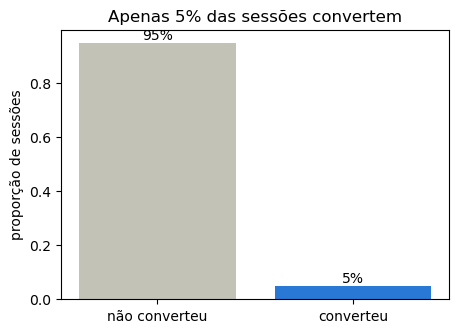

In [21]:
prop = df['converted'].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(['não converteu', 'converteu'], prop, color=[CINZA, AZUL])
for i, v in enumerate(prop):
    ax.text(i, v, f'{v:.0%}', ha='center', va='bottom')
ax.set_title('Apenas 5% das sessões convertem')
ax.set_ylabel('proporção de sessões')
plt.show()

**Resposta:** dataset bem desbalanceado — só 5% das sessões convertem. Métricas e limiares de decisão precisam levar isso em conta.

### Pergunta 2 — Algum usuário converte mais de uma vez?

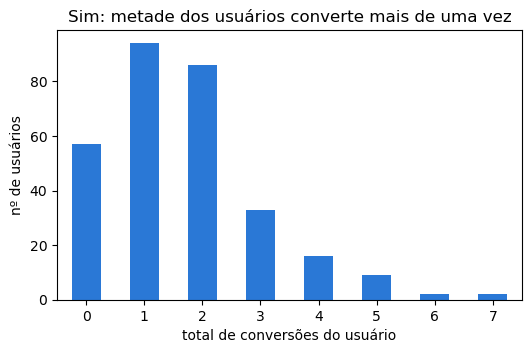

In [22]:
conv_por_usuario = df.groupby('user_id')['converted'].sum()

fig, ax = plt.subplots(figsize=(6, 3.5))
conv_por_usuario.value_counts().sort_index().plot.bar(ax=ax, color=AZUL, rot=0)
ax.set_title('Sim: metade dos usuários converte mais de uma vez')
ax.set_xlabel('total de conversões do usuário')
ax.set_ylabel('nº de usuários')
plt.show()

**Resposta:** sim — conversão não é um evento único por usuário: 81% convertem pelo menos uma vez e ~metade (148 de 299) converte mais de uma vez. Exemplo abaixo: usuário 57 converte 3 vezes.

In [23]:
df[df['user_id'] == 57]

,session_id,user_id,articles_viewed,avg_scroll_depth,total_time_spent,is_weekend,device,converted
350,1350,57,3,71.921969,1427.083999,0,desktop,1
579,1579,57,2,84.028716,109.367949,0,mobile,0
742,1742,57,3,51.313418,1279.484306,1,tablet,1
981,1981,57,4,60.225543,227.421558,0,mobile,0
1040,2040,57,0,95.640632,168.546239,1,mobile,0
1051,2051,57,3,59.458558,158.121133,1,mobile,0
2624,3624,57,2,53.790169,99.154768,1,desktop,0
2914,3914,57,2,23.985546,190.404076,0,mobile,0
3018,4018,57,4,56.330960,175.884254,0,tablet,0
3086,4086,57,3,81.277604,42.388812,0,tablet,0


### Pergunta 3 — Sessões que convertem duram mais?

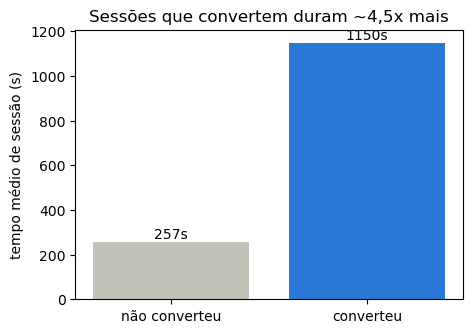

In [24]:
tempo_medio = df.groupby('converted')['total_time_spent'].mean()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(['não converteu', 'converteu'], tempo_medio, color=[CINZA, AZUL])
for i, v in enumerate(tempo_medio):
    ax.text(i, v, f'{v:.0f}s', ha='center', va='bottom')
ax.set_title('Sessões que convertem duram ~4,5x mais')
ax.set_ylabel('tempo médio de sessão (s)')
plt.show()

**Resposta:** sim — 1.150s vs 257s em média (~4,5x). Tempo de sessão é o sinal mais forte de conversão na sessão atual.

### Pergunta 4 — Sessões que convertem leem mais artigos?

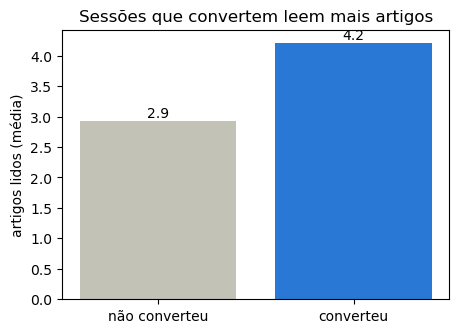

In [25]:
artigos_medio = df.groupby('converted')['articles_viewed'].mean()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(['não converteu', 'converteu'], artigos_medio, color=[CINZA, AZUL])
for i, v in enumerate(artigos_medio):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')
ax.set_title('Sessões que convertem leem mais artigos')
ax.set_ylabel('artigos lidos (média)')
plt.show()

**Resposta:** sim — 4,2 vs 2,9 artigos em média. Diferença real, mas bem menos discriminante que o tempo de sessão.

## 3. Features de histórico do usuário e alvo futuro

Para o modelo "a priori" (prever conversão futura só com o passado), criamos features que usam **apenas informação disponível antes da sessão atual** — todas com `shift()` para evitar vazamento temporal:

| Feature | Descrição |
|---|---|
| `prev_sessions_count` | nº de sessões anteriores do usuário |
| `prev_sessions_time_median` | mediana do tempo das sessões anteriores |
| `cumulative_articles_viewed_before_current_session` | artigos acumulados antes da sessão atual |
| `prev_conversions_count` | conversões anteriores do usuário |
| `will_convert_next_k` | **alvo futuro**: converte em alguma das próximas K=5 sessões? |

**Por que "próximas K sessões" e não "qualquer sessão futura"?** A label ingênua ("converte em alguma sessão futura até o fim da janela observada") sofre de **viés de censura**: perto do fim do dataset ela vai a 0 mecanicamente, por falta de futuro observado — não por comportamento. Como as features acumuladas só crescem com o tempo, isso fabrica correlações espúrias fortes (~−0,39) que um modelo aprenderia como "quem leu muito não converte" — falso em produção. Com horizonte fixo de K sessões e descarte das linhas censuradas (sem K sessões futuras observadas, que ficam `NaN`), a label é comparável em qualquer ponto do tempo e essa correlação colapsa para ~0.

In [26]:
df = df.sort_values(['user_id', 'session_id']).reset_index(drop=True)

# Features de histórico do usuário antes da sessão atual (shift() evita vazamento)
df['prev_sessions_count'] = df.groupby('user_id').cumcount()

df['prev_sessions_time_median'] = (
    df.groupby('user_id')['total_time_spent']
      .transform(lambda x: x.expanding().median().shift().fillna(0))
)

df['cumulative_articles_viewed_before_current_session'] = (
    df.groupby('user_id')['articles_viewed']
      .transform(lambda x: x.cumsum().shift(fill_value=0))
)

df['prev_conversions_count'] = (
    df.groupby('user_id')['converted']
      .transform(lambda x: x.cumsum().shift(fill_value=0))
)

# Alvo futuro SEM viés de censura: converte em alguma das próximas K sessões?
# Linhas sem K sessões futuras observadas ficam NaN (censuradas) e saem da modelagem.
K = 5
df['will_convert_next_k'] = (
    df.groupby('user_id')['converted']
      .transform(lambda x: x[::-1].rolling(K).max().shift(1)[::-1])
)

df = df.sort_values('session_id').reset_index(drop=True)

print(f"linhas censuradas (sem {K} sessões futuras observadas): {df['will_convert_next_k'].isna().sum()} de {len(df)}")
df['will_convert_next_k'].value_counts(normalize=True)

linhas censuradas (sem 5 sessões futuras observadas): 1495 de 10000


will_convert_next_k
0.0    0.767666
1.0    0.232334
Name: proportion, dtype: float64

Conferindo as features no usuário 57 (3 conversões): os contadores acumulam corretamente e `will_convert_next_k` marca 1 nas 5 sessões que antecedem cada conversão; as últimas 5 sessões dele ficam `NaN` (censuradas).

In [27]:
df[df['user_id'] == 57]

,session_id,user_id,articles_viewed,avg_scroll_depth,total_time_spent,is_weekend,device,converted,prev_sessions_count,prev_sessions_time_median,cumulative_articles_viewed_before_current_session,prev_conversions_count,will_convert_next_k
350,1350,57,3,71.921969,1427.083999,0,desktop,1,0,0.000000,0,0,1.0
579,1579,57,2,84.028716,109.367949,0,mobile,0,1,1427.083999,3,1,1.0
742,1742,57,3,51.313418,1279.484306,1,tablet,1,2,768.225974,5,1,0.0
981,1981,57,4,60.225543,227.421558,0,mobile,0,3,1279.484306,8,2,0.0
1040,2040,57,0,95.640632,168.546239,1,mobile,0,4,753.452932,12,2,0.0
1051,2051,57,3,59.458558,158.121133,1,mobile,0,5,227.421558,12,2,0.0
2624,3624,57,2,53.790169,99.154768,1,desktop,0,6,197.983899,15,2,0.0
2914,3914,57,2,23.985546,190.404076,0,mobile,0,7,168.546239,17,2,0.0
3018,4018,57,4,56.330960,175.884254,0,tablet,0,8,179.475157,19,2,0.0
3086,4086,57,3,81.277604,42.388812,0,tablet,0,9,175.884254,23,2,0.0


### Pergunta 5 — Como as features se correlacionam com a conversão?

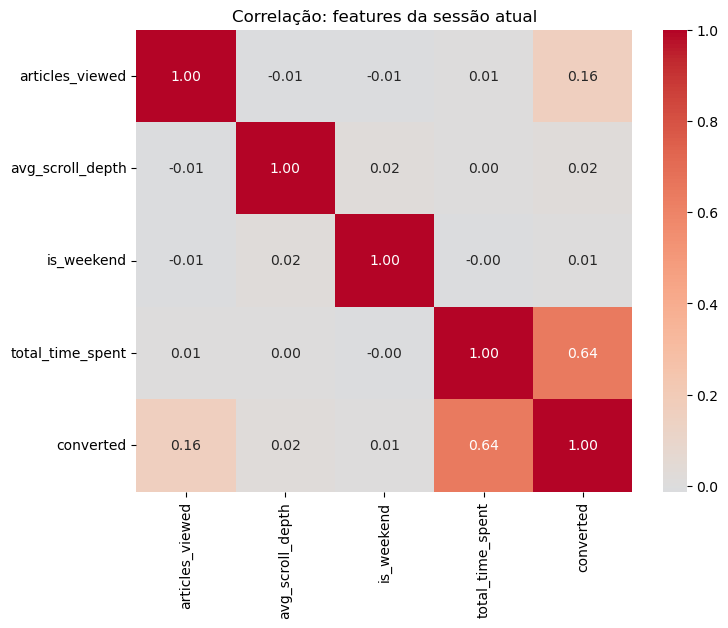

In [46]:
# correlação das features da sessão atual com a conversão
features_sessao = df[['articles_viewed', 'avg_scroll_depth', 'is_weekend', 'total_time_spent', 'converted']]

plt.figure(figsize=(8, 6))
sns.heatmap(features_sessao.corr('pearson'), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlação: features da sessão atual')
plt.show()

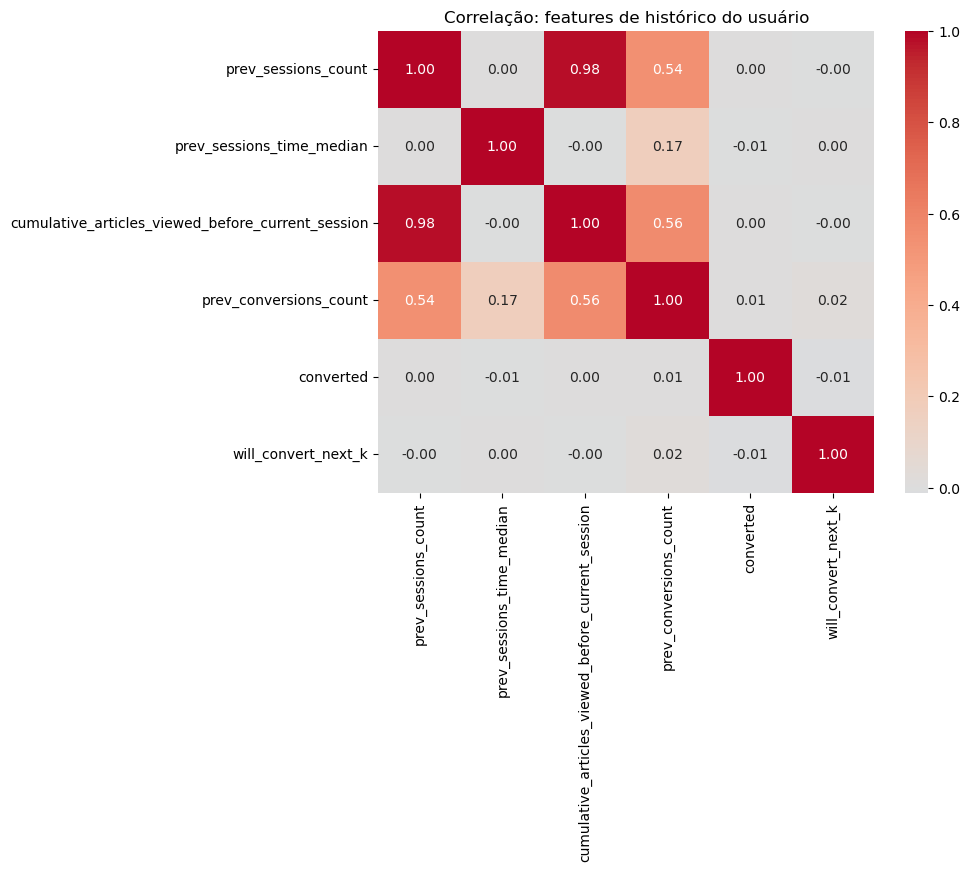

In [29]:
# correlação das features de histórico com a conversão atual e futura
features_historico = df[['prev_sessions_count', 'prev_sessions_time_median',
                         'cumulative_articles_viewed_before_current_session',
                         'prev_conversions_count', 'converted', 'will_convert_next_k']]

plt.figure(figsize=(8, 6))
sns.heatmap(features_historico.corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlação: features de histórico do usuário')
plt.show()

**Resposta:** `total_time_spent` é a feature mais correlacionada com a conversão da sessão atual (0,64); `articles_viewed` vem em seguida (0,16). Já as features de histórico não se correlacionam nem com `converted` nem com o alvo futuro `will_convert_next_k` (todas ≈ 0, a maior é `prev_conversions_count` com 0,02).


### Pergunta 6 — O histórico do usuário ajuda a prever se ele vai converter no futuro?

Se existissem usuários "mais propensos a converter", a taxa de conversão passada de um usuário deveria prever a futura. Dois testes simples, direto nos dados brutos (sem depender de modelo nem de label construída):

1. **Split-half**: correlação entre a taxa de conversão de cada usuário na 1ª metade das próprias sessões e a taxa na 2ª metade.
2. **Sobredispersão**: a variância das taxas por usuário é maior do que a esperada se toda sessão fosse um sorteio independente de 5%?

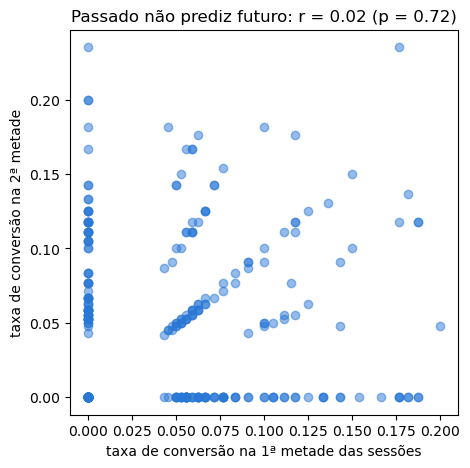

variância observada entre usuários: 0.001455
variância esperada por puro acaso:  0.001468
razão: 0.99  (~1 => nenhuma heterogeneidade real entre usuários)


In [47]:
from scipy import stats

# 1) split-half: taxa de conversão na 1ª metade das sessões do usuário vs na 2ª metade
por_usuario = df.sort_values(['user_id', 'session_id']).groupby('user_id')['converted']
primeira_metade = por_usuario.apply(lambda s: s.iloc[:len(s) // 2].mean())
segunda_metade = por_usuario.apply(lambda s: s.iloc[len(s) // 2:].mean())

r, p_valor = stats.pearsonr(primeira_metade, segunda_metade)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(primeira_metade, segunda_metade, color=AZUL, alpha=0.5)
ax.set_title(f'Passado não prediz futuro: r = {r:.2f} (p = {p_valor:.2f})')
ax.set_xlabel('taxa de conversão na 1ª metade das sessões')
ax.set_ylabel('taxa de conversão na 2ª metade')
plt.show()

# 2) sobredispersão: variância das taxas por usuário vs esperada sob Bernoulli(5%) independente
p_global = df['converted'].mean()
taxas = df.groupby('user_id')['converted'].agg(['mean', 'count'])
var_observada = taxas['mean'].var()
var_esperada = (p_global * (1 - p_global) / taxas['count']).mean()
print(f'variância observada entre usuários: {var_observada:.6f}')
print(f'variância esperada por puro acaso:  {var_esperada:.6f}')
print(f'razão: {var_observada / var_esperada:.2f}  (~1 => nenhuma heterogeneidade real entre usuários)')

**Resposta: não.** A correlação split-half é ~0 (r = 0,02, p = 0,72) e a variância entre usuários é exatamente a prevista pelo acaso (razão ≈ 0,99). A conversão se comporta como um sorteio independente de ~5% por sessão, sem usuários sistematicamente mais propensos.

Consequência importante para a modelagem: qualquer modelo "a priori" baseado só no histórico do usuário tem teto de AUC ≈ 0,5 **por ausência de sinal nos dados, não por limitação do modelo**. A estratégia certa neste dataset é o modelo de sessão em tempo real.

## 4. Modelagem — Regressão Logística × CatBoost

Duas tarefas, mesmo conjunto de dados (linhas censuradas removidas) e mesmo split **cronológico** 80/20 (treina no passado, testa no futuro):

- **Modelo futuro (a priori):** prevê `will_convert_next_k` só com features de histórico + `device`. Serviria para priorizar usuários *antes* de abrirem uma sessão.
- **Modelo da sessão atual:** prevê `converted` com histórico + features da sessão em andamento. Serviria para ações em tempo real (paywall dinâmico, oferta no momento certo).

**Sobre usuários repetidos em treino e teste:** como cada usuário tem ~33 sessões ao longo de toda a janela, o split cronológico mantém os mesmos usuários dos dois lados — **decisão intencional, não descuido**. É o cenário de produção (pontuar sessões futuras de usuários conhecidos), as features de histórico usam apenas sessões estritamente anteriores (`shift()`, seção 3), e não há risco de memorização inflar as métricas: a pergunta 6 mostra que não existe heterogeneidade real entre usuários (split-half r = 0,02; dispersão exatamente binomial) — ou seja, não há "assinatura de usuário" a decorar. Um split por usuário (GroupKFold) responderia outra pergunta — generalização para usuários *novos* — que não é o alvo aqui.

**Métricas — escolhidas para classes desbalanceadas** (5% de positivos na tarefa de sessão, 23% na futura):

| Métrica | Por quê |
|---|---|
| **PR-AUC** (average precision) | a principal em desbalanceamento; o baseline é a taxa de positivos — modelo sem sinal fica nela |
| **Melhor F1** + limiar | qualidade do melhor ponto de operação na curva precision-recall (o limiar 0,5 padrão é inútil com 5% de positivos) |
| **Precision / Recall** no melhor F1 | o trade-off concreto naquele ponto |
| ROC-AUC | referência de ranking, para comparação com a literatura |

**Comparação justa:** a logística usa `class_weight='balanced'`; o CatBoost usa `auto_class_weights='Balanced'` e **early stopping** em um recorte cronológico de validação (sem isso ele overfitta: na tarefa de sessão o ROC-AUC cai de 0,69 para 0,53 com as 1000 árvores default).

In [31]:
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ------------------------------------------------------------
# 1) Features e alvos
# ------------------------------------------------------------

historical_features = [
    'prev_sessions_count',
    'prev_sessions_time_median',
    'cumulative_articles_viewed_before_current_session',
    'prev_conversions_count',
]
current_session_features = ['articles_viewed', 'avg_scroll_depth', 'is_weekend']
categorical_features = ['device']

feature_cols_future = historical_features + categorical_features
feature_cols_session = historical_features + current_session_features + categorical_features

tarefas = {
    'futuro (will_convert_next_k)': (feature_cols_future, 'will_convert_next_k'),
    'sessão (converted)': (feature_cols_session, 'converted'),
}

# ------------------------------------------------------------
# 2) Split cronológico 80/20 (linhas censuradas removidas)
#    + recorte de validação para o early stopping do CatBoost
# ------------------------------------------------------------

model_df = df.dropna(subset=['will_convert_next_k']).copy()
model_df['will_convert_next_k'] = model_df['will_convert_next_k'].astype(int)
model_df['device'] = model_df['device'].fillna('unknown')

split_idx = int(len(model_df) * 0.8)
train = model_df.iloc[:split_idx].copy()
test = model_df.iloc[split_idx:].copy()

val_idx = int(len(train) * 0.8)
fit_part, val_part = train.iloc[:val_idx], train.iloc[val_idx:]

# ------------------------------------------------------------
# 3) Modelos e avaliação
# ------------------------------------------------------------

def make_logistic_pipeline(feature_cols):
    numeric_cols = [c for c in feature_cols if c not in categorical_features]
    preprocessor = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), numeric_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features),
    ])
    return Pipeline([('preprocess', preprocessor),
                     ('clf', LogisticRegression(max_iter=2000, random_state=42, class_weight='balanced'))])

def avaliar(y_true, probas):
    precision, recall, thresholds = precision_recall_curve(y_true, probas)
    f1s = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-9, None)
    i = int(np.argmax(f1s))
    return {'ROC-AUC': roc_auc_score(y_true, probas),
            'PR-AUC': average_precision_score(y_true, probas),
            'melhor F1': f1s[i], 'limiar': thresholds[i],
            'precision': precision[i], 'recall': recall[i]}

resultados = []
for tarefa, (cols, alvo) in tarefas.items():
    print(f'taxa positiva no teste [{tarefa}]: {test[alvo].mean():.3f}  (= baseline do PR-AUC)')

    logistica = make_logistic_pipeline(cols)
    logistica.fit(train[cols], train[alvo])
    resultados.append({'tarefa': tarefa, 'modelo': 'Regressão Logística',
                       **avaliar(test[alvo], logistica.predict_proba(test[cols])[:, 1])})

    catboost = CatBoostClassifier(verbose=False, random_state=42, auto_class_weights='Balanced',
                                  eval_metric='AUC', early_stopping_rounds=50)
    catboost.fit(fit_part[cols], fit_part[alvo],
                 eval_set=(val_part[cols], val_part[alvo]), cat_features=categorical_features)
    resultados.append({'tarefa': tarefa, 'modelo': f'CatBoost ({catboost.tree_count_} árvores)',
                       **avaliar(test[alvo], catboost.predict_proba(test[cols])[:, 1])})

comparacao = pd.DataFrame(resultados).round(4)
comparacao

taxa positiva no teste [futuro (will_convert_next_k)]: 0.235  (= baseline do PR-AUC)
taxa positiva no teste [sessão (converted)]: 0.050  (= baseline do PR-AUC)


,tarefa,modelo,ROC-AUC,PR-AUC,melhor F1,limiar,precision,recall
0,futuro (will_convert_next_k),Regressão Logística,0.4291,0.2049,0.3814,0.4717,0.2359,0.9950
1,futuro (will_convert_next_k),CatBoost (103 árvores),0.5545,0.2872,0.3860,0.1998,0.2397,0.9900
2,sessão (converted),Regressão Logística,0.6990,0.1344,0.1953,0.7101,0.1615,0.2471
3,sessão (converted),CatBoost (47 árvores),0.6933,0.1200,0.2212,0.6377,0.1818,0.2824


**Leitura dos resultados** (baselines de PR-AUC: 0,235 na tarefa futura, 0,050 na de sessão):

**Tarefa futura — nenhum dos dois modelos sai do trivial.**
- Logística: ROC-AUC 0,43 (abaixo de 0,5 = ruído), PR-AUC 0,20 (abaixo do baseline).
- CatBoost: ROC-AUC 0,55, PR-AUC 0,29 — marginalmente acima do baseline, mas o "melhor F1" (~0,38) é atingido com recall ~0,99, ou seja, o ponto ótimo é **chutar todo mundo como positivo** (F1 do classificador trivial: 2×0,235/1,235 = 0,38). Não há ponto de operação útil.

**Tarefa da sessão — sinal real, e os dois modelos empatam.**
- Logística: ROC-AUC 0,70, PR-AUC 0,134 (~2,7× o baseline), melhor F1 0,20.
- CatBoost: ROC-AUC 0,69, PR-AUC 0,120 (~2,4× o baseline), melhor F1 0,22 (precision 0,18 / recall 0,28).

**Por que o CatBoost não ganha da logística na sessão?** O sinal é simples e quase linear — vem essencialmente de `articles_viewed` (a feature de sessão mais informativa aqui, já que `total_time_spent` foi deliberadamente excluída de `feature_cols_session` — a próxima subseção mostra por quê). Capacidade extra de modelo não cria sinal onde a relação já é capturada por um coeficiente; e sem early stopping o CatBoost ainda piora (overfitta para ROC 0,53). A escolha entre os dois aqui seria por critérios operacionais (interpretabilidade e simplicidade favorecem a logística), não por métrica.

### 4.1 Por que `total_time_spent` foi excluído do modelo de sessão

O dataset só tem **agregados de fim de sessão** (tempo total, artigos totais), não eventos com timestamp — não dá para saber com certeza o que o modelo teria disponível no instante exato em que o paywall seria exibido. Sem essa granularidade, a defesa possível é testar quais features são suspeitas demais para confiar: uma feature que separa as classes quase perfeitamente num split cronológico é sinal de que ela carrega informação do próprio desfecho, não de comportamento genuíno anterior à decisão.

In [32]:
# ------------------------------------------------------------
# Teste: quanto o AUC do modelo de sessão muda se incluirmos
# total_time_spent como feature?
# ------------------------------------------------------------

logistica_sem_tempo = make_logistic_pipeline(feature_cols_session)
logistica_sem_tempo.fit(train[feature_cols_session], train['converted'])
auc_sem_tempo = roc_auc_score(test['converted'], logistica_sem_tempo.predict_proba(test[feature_cols_session])[:, 1])

feature_cols_com_tempo = feature_cols_session + ['total_time_spent']
logistica_com_tempo = make_logistic_pipeline(feature_cols_com_tempo)
logistica_com_tempo.fit(train[feature_cols_com_tempo], train['converted'])
auc_com_tempo = roc_auc_score(test['converted'], logistica_com_tempo.predict_proba(test[feature_cols_com_tempo])[:, 1])

print(f'AUC do modelo de sessão SEM total_time_spent: {auc_sem_tempo:.4f}')
print(f'AUC do modelo de sessão COM total_time_spent: {auc_com_tempo:.4f}')

# a relação entre tempo e artigos lidos muda com a conversão?
tmp = df[df['articles_viewed'] > 0].copy()
tmp['tempo_por_artigo'] = tmp['total_time_spent'] / tmp['articles_viewed']

print('\ntempo por artigo (mediana), por classe:')
print(tmp.groupby('converted')['tempo_por_artigo'].median().round(1))

print('\ncorrelação articles_viewed x total_time_spent, por classe:')
print('não converteu:', round(df[df.converted == 0][['articles_viewed', 'total_time_spent']].corr().iloc[0, 1], 3))
print('converteu:    ', round(df[df.converted == 1][['articles_viewed', 'total_time_spent']].corr().iloc[0, 1], 3))

AUC do modelo de sessão SEM total_time_spent: 0.6990
AUC do modelo de sessão COM total_time_spent: 0.9999

tempo por artigo (mediana), por classe:
converted
0     67.9
1    274.4
Name: tempo_por_artigo, dtype: float64

correlação articles_viewed x total_time_spent, por classe:
não converteu: -0.086
converteu:     -0.522


**Resultado:** incluir `total_time_spent` leva o AUC de teste de 0,70 para **~1,00** — separação quase perfeita, algo que nenhuma feature de comportamento humano deveria produzir num split cronológico (o modelo nunca viu essas sessões de teste). É a assinatura clássica de leakage: o valor registrado é o tempo **total da sessão inteira**, incluindo o que aconteceu depois da própria conversão (fluxo de checkout, navegação sem paywall etc.) — não só o tempo até o instante em que a decisão seria tomada.

A evidência aparece também na relação entre tempo e leitura: nas sessões que não convertem, tempo e artigos lidos têm correlação fraca (≈ −0,09); nas que convertem, a correlação cai para **≈ −0,52** e o tempo por artigo sobe de ~68s (mediana) para ~274s. Ou seja, nas sessões convertidas o tempo deixa de acompanhar a leitura e passa a ser dominado por outra coisa — consistente com tempo pós-conversão contaminando a feature.

## 5. Teto de sinal — por que o modelo futuro não funciona

O resultado ruim da tarefa futura não é defeito de modelo nem de label. As evidências (pergunta 6 + experimentos à parte, sem código aqui):

1. **Split-half:** a taxa de conversão de cada usuário na 1ª metade das próprias sessões não correlaciona com a 2ª metade (r = 0,02, p = 0,72).
2. **Sobredispersão:** a variância das taxas por usuário é exatamente a prevista se cada sessão fosse um sorteio independente de 5% (razão observado/esperado = 0,99, χ² p = 0,39).

**Conclusão:** a conversão neste dataset se comporta como um evento independente por sessão (~5%), modulado apenas pelo engajamento *daquela* sessão. O teto do modelo a priori é AUC ≈ 0,5 por **ausência de sinal nos dados** — nenhuma feature de histórico, horizonte ou modelo muda isso.

## 7. Respostas às perguntas do teste

Síntese em pontos-chave para apresentação. Cada resposta traz a evidência (número, tabela ou gráfico) logo abaixo; o desenvolvimento completo está nas seções 1–6. *(Depende das células anteriores — executar o notebook do início.)*

### P1 — Janela de tempo dos dados de treino e data leakage intra-sessão

- **Janela:** sem coluna de data/hora, `session_id` crescente é o proxy temporal (premissa declarada na seção 1). **Split cronológico 80/20** — treina no passado, testa no futuro, como em produção; a validação do early stopping também é um recorte cronológico do treino
- **Princípio anti-leakage:** só entra como feature o que é conhecido **no instante em que o paywall é exibido**
- **`total_time_spent` excluída:** é a duração total da sessão — só conhecida quando ela acaba, contaminada pelo pós-conversão. Não excluí por palpite: **testei** — incluí-la leva o AUC de teste de 0,70 a ~1,00 (seção 4.1), assinatura clássica de vazamento
- **Histórico do usuário sem vazamento:** janela expansível com `shift()` — apenas sessões estritamente anteriores à atual (seção 3)
- **Usuários repetidos em treino e teste: intencional** — reflete produção (pontuar sessões futuras de usuários conhecidos) e não infla métricas: não há heterogeneidade entre usuários a memorizar (split-half r = 0,02 — seção 5)
- **Label futura sem viés de censura:** horizonte fixo `will_convert_next_k` (K=5) com descarte das linhas censuradas — a label ingênua fabricaria correlações espúrias de −0,39 (seção 3)

### P2 — As 3 features mais correlacionadas com a conversão. Por que foram relevantes?

- **Top 3: `total_time_spent` (0,64), `articles_viewed` (0,16), `avg_scroll_depth` (0,02)** — todas de engajamento da sessão atual; as de histórico do usuário ficam todas ≈ 0
- **Por que relevantes:** conversão acontece quando o usuário está engajado *agora* — mais leitura, mais tempo, mais rolagem. É o estado da sessão, não o perfil da pessoa, que carrega o sinal
- **A mais forte é justamente vazamento**
- **O sinal utilizável em produção é `articles_viewed`:** gradiente monotônico de conversão de 1,6% (0–1 artigos) a 14,8% (6+) — ver P8

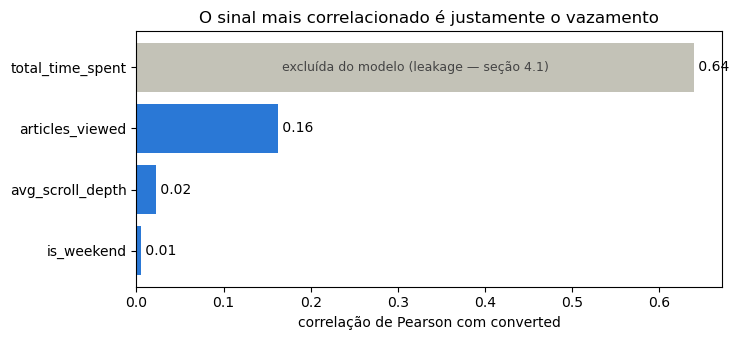

In [33]:
# Evidência P2: correlação de cada feature da sessão com a conversão
corr = (df[['total_time_spent', 'articles_viewed', 'avg_scroll_depth', 'is_weekend']]
        .corrwith(df['converted']).sort_values())

cores = [CINZA if f == 'total_time_spent' else AZUL for f in corr.index]
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.barh(corr.index, corr.values, color=cores)
for i, v in enumerate(corr.values):
    ax.text(v, i, f' {v:.2f}', va='center')
ax.text(corr['total_time_spent'] / 2, list(corr.index).index('total_time_spent'),
        'excluída do modelo (leakage — seção 4.1)', va='center', ha='center', color='#444', fontsize=9)
ax.set_title('O sinal mais correlacionado é justamente o vazamento')
ax.set_xlabel('correlação de Pearson com converted')
plt.tight_layout()
plt.show()

### P3 — Critério de escolha do modelo

- **Comparação controlada** Regressão Logística × CatBoost: mesmo split cronológico
- **Critério primário: PR-AUC no teste out-of-time** — a métrica adequada com 5% de positivos; ROC-AUC como referência secundária
- **Resultado: empate técnico na tarefa com sinal** (logística 0,70/0,134 vs CatBoost 0,69/0,120 em ROC/PR-AUC) — o sinal é simples e quase linear, capacidade extra de modelo não cria sinal que não existe
- **Desempate por critérios operacionais → Regressão Logística**

In [34]:
# Evidência P3: comparação controlada dos dois modelos nas duas tarefas (seção 4)
comparacao

,tarefa,modelo,ROC-AUC,PR-AUC,melhor F1,limiar,precision,recall
0,futuro (will_convert_next_k),Regressão Logística,0.4291,0.2049,0.3814,0.4717,0.2359,0.9950
1,futuro (will_convert_next_k),CatBoost (103 árvores),0.5545,0.2872,0.3860,0.1998,0.2397,0.9900
2,sessão (converted),Regressão Logística,0.6990,0.1344,0.1953,0.7101,0.1615,0.2471
3,sessão (converted),CatBoost (47 árvores),0.6933,0.1200,0.2212,0.6377,0.1818,0.2824


### P4 — Como evitar o modelo "preguiçoso" que só prevê a classe majoritária?

- **Reponderação de classes:** `class_weight='balanced'` na logística e `auto_class_weights='Balanced'` no CatBoost — o erro num convertedor passa a pesar ~19× mais
- **Métricas que não premiam a preguiça:** PR-AUC (baseline explícito = 5%), melhor F1, precision/recall — nunca acurácia (ver P5)
- **Limiar de decisão da curva precision-recall**, não o 0,5 padrão — que com 5% de positivos não marca ninguém
- **Sem reamostragem (SMOTE/undersampling), deliberadamente** 

### P5 — Acurácia de 98% sem identificar nenhum assinante: é útil? Quais métricas priorizar?

- **Não é útil — é o classificador trivial disfarçado.** Com base rate de 5%, chutar "ninguém converte" já garante 95% de acurácia identificando **zero** assinantes (evidência abaixo). Acurácia alta mede o desbalanceamento, não o modelo
- **Métricas priorizadas, em ordem:**
  - **PR-AUC** (average precision) — a principal: seu baseline é a taxa de positivos (5%), então qualquer valor acima indica sinal real; ignora os verdadeiros negativos abundantes
  - **Recall** no ponto de operação — cada FN é uma assinatura (LTV) perdida
  - **Precision** no ponto de operação — controla o custo de irritação dos FPs
  - **F1** — resume o ponto de operação para comparar modelos
  - **ROC-AUC** — referência de ranking para comparação com a literatura, mas otimista sob desbalanceamento (inflada pelos negativos fáceis)

In [36]:
# Evidência P5: classificador trivial vs modelo de sessão no teste
from sklearn.metrics import accuracy_score

y_test = test['converted'].values
probas_lr = logistica_sem_tempo.predict_proba(test[feature_cols_session])[:, 1]
res = avaliar(y_test, probas_lr)

pred_trivial = np.zeros_like(y_test)
pred_modelo = (probas_lr >= res['limiar']).astype(int)

comparativo = pd.DataFrame({
    'acurácia': [accuracy_score(y_test, pred_trivial), accuracy_score(y_test, pred_modelo)],
    'precision': [0.0, res['precision']],
    'recall': [0.0, res['recall']],
    'assinantes identificados': [0, int(((pred_modelo == 1) & (y_test == 1)).sum())],
    'assinantes no teste': [int(y_test.sum())] * 2,
}, index=['trivial: "ninguém converte"', f'modelo de sessão (limiar {res["limiar"]:.2f})']).round(3)
comparativo

,acurácia,precision,recall,assinantes identificados,assinantes no teste
"trivial: ""ninguém converte""",0.950,0.000,0.000,0,85
modelo de sessão (limiar 0.71),0.898,0.162,0.247,21,85


### P6 — "Por que o paywall apareceu para este usuário que só leu uma notícia?"

- **Feature Importance global** responde "o que o modelo considera em geral" — útil para validar o modelo, insuficiente para explicar um caso
- **SHAP responde caso a caso:** decompõe a probabilidade *daquele* usuário na contribuição de cada feature, somando exatamente até a predição — é a ferramenta certa para a pergunta do diretor
- **A resposta concreta:** "ele leu só 1 notícia (contribuição negativa, em cinza no gráfico), mas os demais sinais da sessão — scroll, contexto, histórico — empurraram a probabilidade acima do limiar (barras azuis)". Evidência abaixo: a sessão real do teste com ≤1 artigo que recebeu a maior probabilidade, decomposta com SHAP nativo do CatBoost

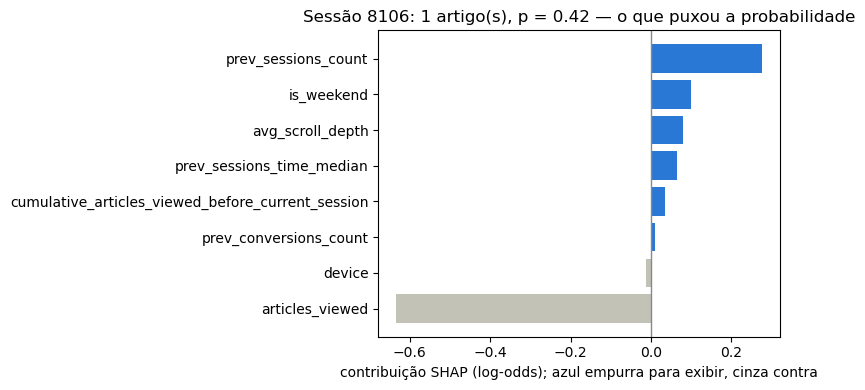

Valores da sessão explicada:
prev_sessions_count                                          26
prev_sessions_time_median                            102.165578
cumulative_articles_viewed_before_current_session            84
prev_conversions_count                                        0
articles_viewed                                               1
avg_scroll_depth                                      39.763818
is_weekend                                                    0
device                                                  desktop
Name: 7106, dtype: object


In [37]:
# Evidência P6: SHAP nativo do CatBoost — explicação local de uma decisão
from catboost import Pool

catboost_sessao = CatBoostClassifier(verbose=False, random_state=42, auto_class_weights='Balanced',
                                     eval_metric='AUC', early_stopping_rounds=50)
catboost_sessao.fit(fit_part[feature_cols_session], fit_part['converted'],
                    eval_set=(val_part[feature_cols_session], val_part['converted']),
                    cat_features=categorical_features)

test_pool = Pool(test[feature_cols_session], label=test['converted'], cat_features=categorical_features)
shap_vals = catboost_sessao.get_feature_importance(test_pool, type='ShapValues')  # última coluna = valor base
probas_cb = catboost_sessao.predict_proba(test[feature_cols_session])[:, 1]

# o caso do diretor: a sessão com <=1 artigo lido que recebeu a MAIOR probabilidade do modelo
mask = test['articles_viewed'].values <= 1
i = int(np.argmax(np.where(mask, probas_cb, -1)))
sessao = test.iloc[i]

contrib = pd.Series(shap_vals[i, :-1], index=feature_cols_session).sort_values()
cores = [AZUL if v > 0 else CINZA for v in contrib.values]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(contrib.index, contrib.values, color=cores)
ax.axvline(0, color='#888', lw=1)
ax.set_title(f'Sessão {sessao["session_id"]:.0f}: {sessao["articles_viewed"]:.0f} artigo(s), '
             f'p = {probas_cb[i]:.2f} — o que puxou a probabilidade')
ax.set_xlabel('contribuição SHAP (log-odds); azul empurra para exibir, cinza contra')
plt.tight_layout()
plt.show()

print('Valores da sessão explicada:')
print(sessao[feature_cols_session])

### P7 — Como definir a probabilidade mínima para exibir o paywall? E o custo do falso positivo?

- **O limiar é decisão econômica, não estatística:** exibir quando $$p·V > (1−p)·C,$$ limiar ótimo **p\* = C/(C+V)**, onde V = LTV da assinatura e C = custo do falso positivo
- **O custo de "irritar um fiel" é mensurável nestes dados:** como a conversão é ~independente por sessão (5%, seções 5–6), irritar um usuário custa as sessões futuras perdidas, cada uma valendo `receita de ads + 0,05 × LTV`. O medo vira um número — e entra no C
- **Cuidado com calibração:** `class_weight='balanced'` distorce as probabilidades; a fórmula p\* exige recalibração (Platt/isotônica).
- **V e C não estão no dataset** (não há preço, LTV nem receita de ads)
- O *momento* ótimo de exibição dentro da sessão exigiria clickstream com timestamp por evento (não disponível — seção 4.1)

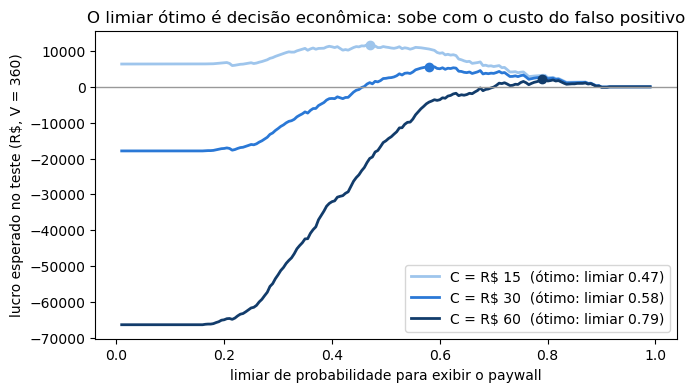

In [ ]:
# Evidência P7: varredura empírica de lucro esperado no teste, por limiar
# (dispensa calibração: usa os rótulos reais, não as probabilidades como frequência)
V = 360.0                       # exemplo: LTV anual da assinatura (R$)
custos_fp = [15.0, 30.0, 60.0]  # exemplo: custo de irritar um não-convertedor (R$)
tons = ['#9ec5ec', '#2a78d6', '#123c6b']  # mesmo azul, claro -> escuro: custo crescente

ths = np.linspace(0.01, 0.99, 197)
fig, ax = plt.subplots(figsize=(7.5, 4))
for C, tom in zip(custos_fp, tons):
    ev = np.array([V * ((probas_lr >= t) & (y_test == 1)).sum()
                   - C * ((probas_lr >= t) & (y_test == 0)).sum() for t in ths]) # V * probas_lr >= t) & (y_test == 1)).sum()  # lucro esperado: receita - custo
    i = int(ev.argmax())
    ax.plot(ths, ev, color=tom, lw=2, label=f'C = R$ {C:.0f}  (ótimo: limiar {ths[i]:.2f})')
    ax.scatter([ths[i]], [ev[i]], color=tom, zorder=3)

ax.axhline(0, color='#999', lw=1)
ax.set_title('O limiar ótimo é decisão econômica: sobe com o custo do falso positivo')
ax.set_xlabel('limiar de probabilidade para exibir o paywall')
ax.set_ylabel(f'lucro esperado no teste (R$, V = {V:.0f})')
ax.legend()
plt.show()

### P8 — Em quais categorias de notícias ou perfis de usuários ser mais agressivo?

- **Categorias de notícias: não há como responder com estes dados** 
- **Perfis estáveis de usuário: também não — e isso é um resultado, não uma omissão.** Não existe heterogeneidade real entre usuários (split-half r = 0,02; dispersão exatamente binomial — seções 5–6). Propensão a converter não é atributo da *pessoa*, é estado da *sessão*
- **Onde ser agressivo: sessões de alto engajamento.** A conversão sobe monotonicamente com artigos lidos na sessão: **1,6% (0–1 artigos) → 7,9% (5) → 14,8% (6+)** — gradiente de ~9×. Bloqueio agressivo em sessões com ≥5 artigos
- **Onde ser conservador: sessões frias (0–1 artigos)** — conversão esperada de 1,6% raramente cobre o custo de irritação do falso positivo (coerente com o limiar econômico da P7)
- **Device e fim de semana: não segmentar** — conversão ~5% em todos os recortes, sem poder discriminante

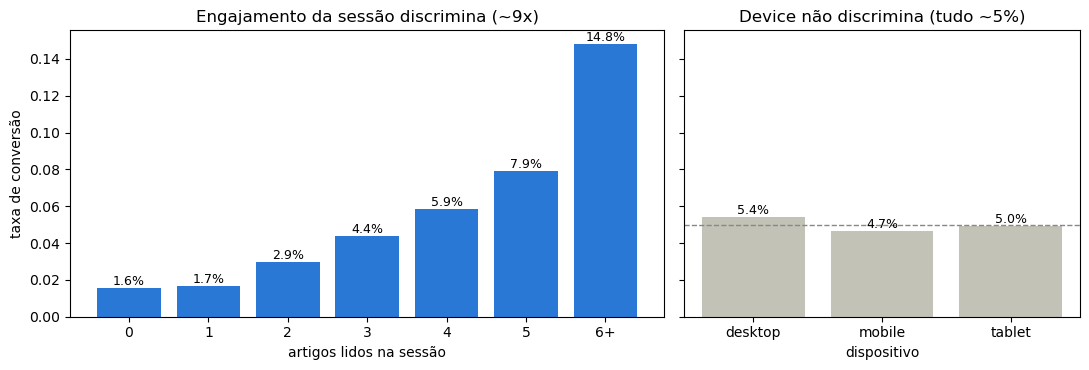

In [39]:
# Evidência P8: gradiente por engajamento da sessão vs recortes planos
conv_art = df.assign(artigos=df['articles_viewed'].clip(upper=6)).groupby('artigos')['converted'].mean()
conv_dev = df.groupby('device')['converted'].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [3, 2]}, sharey=True)

rotulos = ['0', '1', '2', '3', '4', '5', '6+']
axes[0].bar(rotulos, conv_art.values, color=AZUL)
for i, v in enumerate(conv_art.values):
    axes[0].text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Engajamento da sessão discrimina (~9x)')
axes[0].set_xlabel('artigos lidos na sessão')
axes[0].set_ylabel('taxa de conversão')

axes[1].bar(conv_dev.index, conv_dev.values, color=CINZA)
for i, v in enumerate(conv_dev.values):
    axes[1].text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=9)
axes[1].axhline(df['converted'].mean(), color='#888', lw=1, ls='--')
axes[1].set_title('Device não discrimina (tudo ~5%)')
axes[1].set_xlabel('dispositivo')

plt.tight_layout()
plt.show()